# tinyrl

In [19]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import scipy

In [20]:
CHECKPOINT_DIR = "./checkpoints"

AVG_FILTER_SIZE = 10
ALPHA_MEAN = 0.9
ALPHA_STD = 0.2

ENV_ORDER = [
    "Hopper-v5",
    "Walker2d-v5",
    "HalfCheetah-v5",
    "Humanoid-v5",
    "Ant-v5",
]

ALG_COLORS = {
    "ddpg": "blue", 
    "td3": "green", 
    "sac": "red"
}

ALG_NAMES = {
    "ddpg": "DDPG", 
    "td3": "TD3",
    "sac": "SAC"
}

In [ ]:
def collect_runs_over_seed(algorithm: str, checkpoints_dir: str = "./checkpoints/") -> pd.DataFrame:
    path = os.path.join(checkpoints_dir, algorithm)

    dfs = []
    for dir_name in os.listdir(path):
        dir_path = os.path.join(path, dir_name)

        if not os.path.isdir(dir_path):
            continue

        for file_name in os.listdir(dir_path):
            if file_name.endswith(".csv"):
                df = pd.read_csv(os.path.join(dir_path, file_name))
                df["env"] = dir_name.split("-")[0] + "-v5"
                df["step (in 10k)"] = range(len(df))
                dfs.append(df)

    combined = pd.concat(dfs, ignore_index=True)

    result = (
        combined
        .groupby(["env", "step"])
        .agg(
            mean_rewards=("average_rewards", "mean"),
            std_rewards=("average_rewards", "std")
        ).reset_index()
    )

    return result

In [22]:
df = collect_runs_over_seed("ddpg")

In [23]:
df

,env,step,mean_rewards,std_rewards
0,ant-v5,0,87.201701,27.855152
1,ant-v5,1,12.499766,5.094743
2,ant-v5,2,45.425392,80.931640
3,ant-v5,3,30.186244,28.773263
4,ant-v5,4,193.382357,114.628703
...,...,...,...,...
495,walker2d-v5,95,1709.112600,1249.095978
496,walker2d-v5,96,2013.580953,1110.360425
497,walker2d-v5,97,1555.091766,997.859911
498,walker2d-v5,98,738.201902,1031.873980


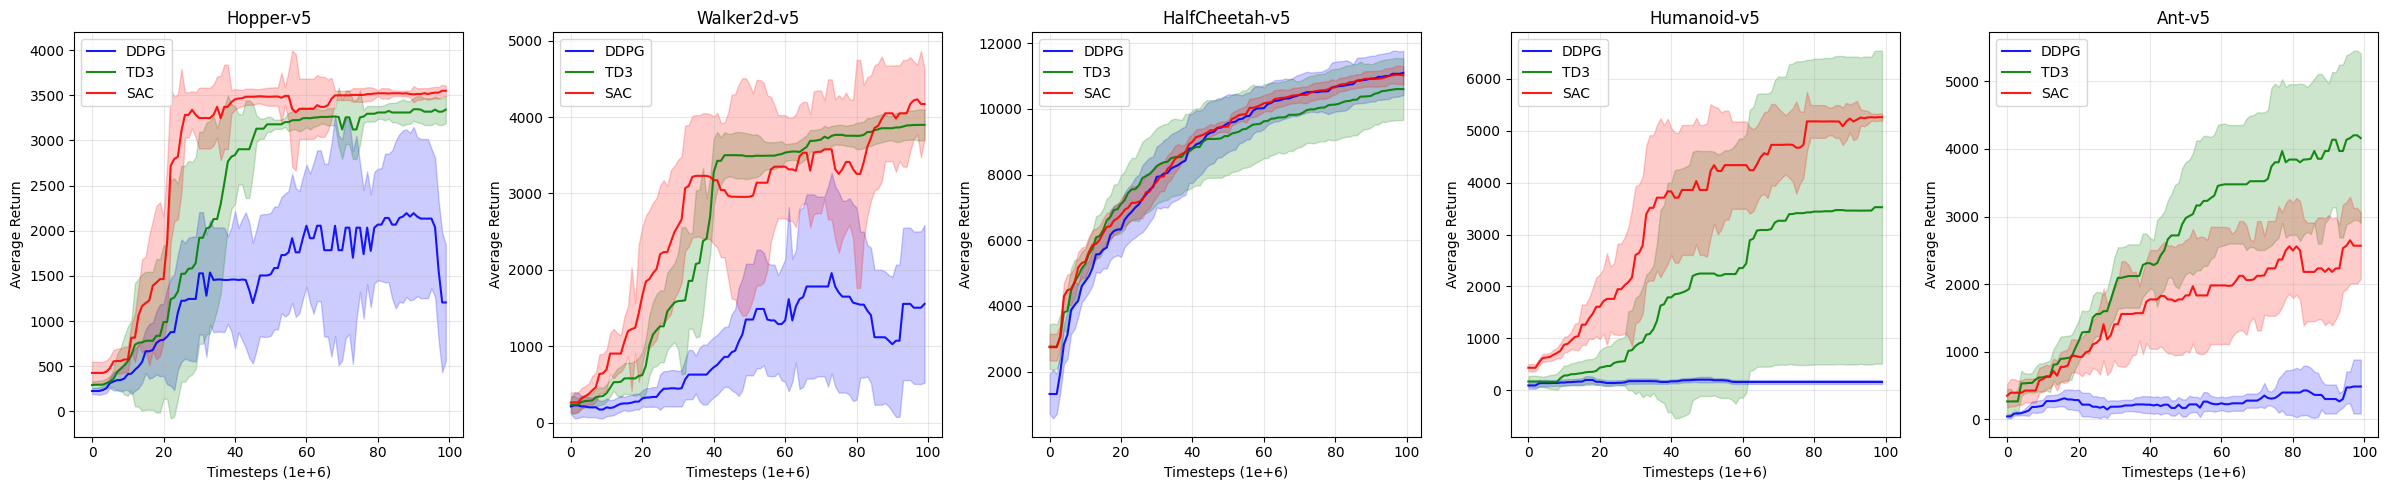

In [24]:
fig, ax = plt.subplots(nrows=1, ncols=5, figsize=(24, 5))
ax = ax.flatten()

for alg in ALG_NAMES.keys():
    df = collect_runs_over_seed(alg, CHECKPOINT_DIR)
    
    for i, env_name in enumerate(ENV_ORDER):
        df_env = df[df["env"] == env_name.lower()]

        timesteps = df_env["step"]

        #mean = df_env["mean_rewards"]
        mean = scipy.ndimage.median_filter(
            df_env["mean_rewards"],
            size=AVG_FILTER_SIZE,
         )

        std = scipy.ndimage.median_filter(
            df_env["std_rewards"].fillna(0),
            size=AVG_FILTER_SIZE,
        )

        lower = mean - std
        upper = mean + std

        ax[i].plot(
            timesteps,
            mean,
            label=ALG_NAMES[alg],
            color=ALG_COLORS[alg],
            alpha=ALPHA_MEAN,
        )

        ax[i].fill_between(
            timesteps,
            lower,
            upper,
            color=ALG_COLORS[alg],
            alpha=ALPHA_STD,
        )

        ax[i].set_title(env_name)
        ax[i].set_xlabel("Timesteps (1e+6)")
        ax[i].set_ylabel("Average Return")
        ax[i].grid(alpha=0.3)
        ax[i].legend()

plt.tight_layout()
plt.show()